# NBA Regular-Season EDA (1996–97 to 2022–23)

## Introduction

For this project, we used NBA data to look at shooting, scoring, and winning. We tested these six hypotheses:

1. Centers are taking more shots, especially three-pointers.
2. Point guards score a larger share of NBA points than they used to.
3. Teams that make more three-pointers tend to win more games.
4. Teams with higher field-goal percentages tend to win more games.
5. Teams with fewer turnovers tend to win more games.
6. NBA teams scored more points per game in 2022–23 than in 1996–97.

We used Pandas to compare the stats and made graphs to see whether each prediction was supported.

## About the dataset

The data covers NBA regular seasons from 1996–97 through 2022–23. It includes player stats, positions, and team stats. For the team data, each row shows one team's numbers for a season.

Some columns we used are:

- `SEASON`: NBA season
- `FG3A` and `FG3M`: three-point attempts and makes per game
- `FG_PCT`: field-goal percentage
- `TOV`: turnovers per game
- `PTS`: points per game
- `W_PCT`: win percentage

We also used player positions and points to compare centers and point guards. The main NBA stats came from the Brescou NBA dataset, and the extra position data came from FiveThirtyEight. The extra position file ends in 2019–20, so Hypothesis 2 covers fewer seasons.

## Loading the data

We load the player and team CSV files with Pandas. If the files are not already in the data folder, the next cell gets them from their original sources.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data")

sources = {
    DATA_DIR / "player/player_stats_traditionnal_rs.csv": "https://raw.githubusercontent.com/Brescou/NBA-dataset-stats-player-team/main/player/player_stats_traditionnal_rs.csv",
    DATA_DIR / "player/player_index.csv": "https://raw.githubusercontent.com/Brescou/NBA-dataset-stats-player-team/main/player/player_index.csv",
    DATA_DIR / "team/team_stats_traditional_rs.csv": "https://raw.githubusercontent.com/Brescou/NBA-dataset-stats-player-team/main/team/team_stats_traditional_rs.csv",
    DATA_DIR / "external/nba-data-historical.csv": "https://raw.githubusercontent.com/fivethirtyeight/nba-player-advanced-metrics/master/nba-data-historical.csv"
}

for path, url in sources.items():
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        pd.read_csv(url).to_csv(path, index=False)

player_raw = pd.read_csv(DATA_DIR / "player/player_stats_traditionnal_rs.csv")
index_raw = pd.read_csv(DATA_DIR / "player/player_index.csv")
team_raw = pd.read_csv(DATA_DIR / "team/team_stats_traditional_rs.csv")
position_raw = pd.read_csv(DATA_DIR / "external/nba-data-historical.csv")

print("Player rows:", len(player_raw))
print("Team rows:", len(team_raw))
team_raw.head()

Player rows: 12846
Team rows: 802


,TEAM_ID,TEAM_NAME,GP,W,L,W_PCT,MIN,FGM,FGA,FG_PCT,...,AST_RANK,TOV_RANK,STL_RANK,BLK_RANK,BLKA_RANK,PF_RANK,PFD_RANK,PTS_RANK,PLUS_MINUS_RANK,SEASON
0,1610612737,Atlanta Hawks,82,56,26,0.683,48.3,34.3,76.9,0.446,...,28,7,9,11,4,1,27,23,5,1996-97
1,1610612738,Boston Celtics,82,15,67,0.183,48.5,37.4,85.0,0.440,...,15,22,2,27,29,22,21,5,27,1996-97
2,1610612766,Charlotte Hornets,82,54,28,0.659,48.3,36.4,77.3,0.471,...,4,5,26,22,6,6,9,12,11,1996-97
3,1610612741,Chicago Bulls,82,69,13,0.841,48.1,40.0,84.4,0.473,...,2,2,7,25,2,3,7,1,1,1996-97
4,1610612739,Cleveland Cavaliers,82,42,40,0.512,48.4,33.0,72.8,0.453,...,19,4,16,27,7,19,4,29,12,1996-97


## Preparing the data

We add the player positions and season years. We also calculate season totals using the per-game numbers and games played. This lets us compare players across different seasons.

In [18]:
players = player_raw.merge(index_raw[["PERSON_ID", "POSITION"]],
                           left_on="PLAYER_ID", right_on="PERSON_ID", how="left")
teams = team_raw.copy()

players["season_end"] = players["SEASON"].str[:4].astype(int) + 1
teams["season_end"] = teams["SEASON"].str[:4].astype(int) + 1

players["fga_tot"] = players["FGA"] * players["GP"]
players["fg3a_tot"] = players["FG3A"] * players["GP"]
players["points_tot"] = players["PTS"] * players["GP"]

# Remove player-season rows that list more games than any team played that season.
max_games = teams.groupby("SEASON")["GP"].max()
players["bad_games"] = players["GP"] > players["SEASON"].map(max_games)

h1_players = players[(players["bad_games"] == False) & players["POSITION"].notna()]

def season_rates(data, position_col):
    totals = data.groupby(["SEASON", "season_end", position_col])[[
        "GP", "fga_tot", "fg3a_tot", "points_tot"
    ]].sum().reset_index()
    totals["fga_per_game"] = totals["fga_tot"] / totals["GP"]
    totals["fg3a_per_game"] = totals["fg3a_tot"] / totals["GP"]
    return totals

## Hypothesis 1: Centers are taking more shots, especially three-pointers.

We looked at the average shots attempted by centers each season. We compared all field-goal attempts with three-point attempts.

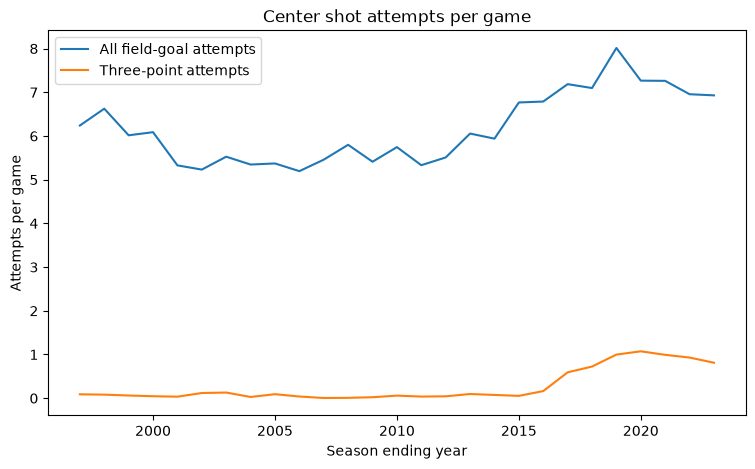

1996-97 three-point attempts: 0.09
2022-23 three-point attempts: 0.81
1996-97 field-goal attempts: 6.24
2022-23 field-goal attempts: 6.93


In [19]:
h1 = season_rates(h1_players, "POSITION")
centers = h1[h1["POSITION"] == "C"].sort_values("season_end")

plt.figure(figsize=(9, 5))
plt.plot(centers["season_end"], centers["fga_per_game"], label="All field-goal attempts")
plt.plot(centers["season_end"], centers["fg3a_per_game"], label="Three-point attempts")
plt.title("Center shot attempts per game")
plt.xlabel("Season ending year")
plt.ylabel("Attempts per game")
plt.legend()
plt.show()

print("1996-97 three-point attempts:", round(centers.iloc[0]["fg3a_per_game"], 2))
print("2022-23 three-point attempts:", round(centers.iloc[-1]["fg3a_per_game"], 2))
print("1996-97 field-goal attempts:", round(centers.iloc[0]["fga_per_game"], 2))
print("2022-23 field-goal attempts:", round(centers.iloc[-1]["fga_per_game"], 2))

### Results

Center three-point attempts went from about 0.09 per game in 1996–97 to 0.81 in 2022–23. Their total field-goal attempts also went up a little, from about 6.24 to 6.93 per game. The graph shows that centers started taking a lot more threes over time. This supports our hypothesis.

## Hypothesis 2: Point guards score a larger share of NBA points than they used to.

We used the position data to identify point guards and compared their share of scoring by season. The position file only goes through 2019–20.

In [20]:

def simplify_name(names):
    return (names.astype(str).str.lower()
            .str.replace(r"[.'’\-]", "", regex=True)
            .str.replace(r"\s+", " ", regex=True).str.strip())

raptor = position_raw.loc[position_raw["type"] == "RS"].copy()
raptor = raptor.sort_values("Min", ascending=False).drop_duplicates(["player_id", "year_id"])
raptor["name_key"] = simplify_name(raptor["name_common"])

h2_base = players.loc[
    ~players["bad_games"] & players["season_end"].between(1997, 2020)
].copy()
h2_base["name_key"] = simplify_name(h2_base["PLAYER_NAME"])

# Some player names refer to more than one person, so we skip those matches.
nba_counts = h2_base.groupby(["name_key", "season_end"])["PLAYER_ID"].nunique()
raptor_counts = raptor.groupby(["name_key", "year_id"])["player_id"].nunique()
ambiguous = set(nba_counts[nba_counts > 1].index) | set(raptor_counts[raptor_counts > 1].index)

def keep_unambiguous(df, year_col):
    keys = pd.MultiIndex.from_arrays([df["name_key"], df[year_col]])
    return df.loc[~keys.isin(ambiguous)].copy()

h2_base = keep_unambiguous(h2_base, "season_end")
raptor = keep_unambiguous(raptor, "year_id")

h2_joined = h2_base.merge(
    raptor[["name_key", "year_id", "pos"]],
    left_on=["name_key", "season_end"], right_on=["name_key", "year_id"],
    how="left"
)
h2_players = h2_joined[h2_joined["pos"].notna()].copy()


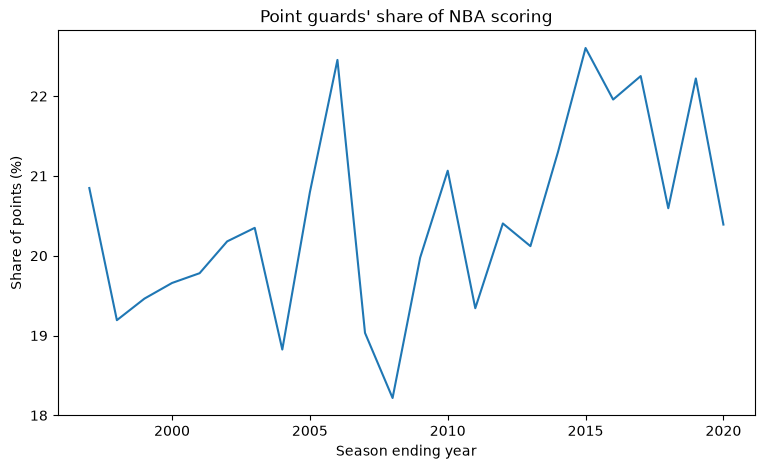

1996-97 share: 20.8 %
2019-20 share: 20.4 %


In [21]:
h2 = season_rates(h2_players, "pos")
season_points = h2_players.groupby("season_end")["points_tot"].sum()
h2["all_points"] = h2["season_end"].map(season_points)
h2["scoring_share"] = h2["points_tot"] / h2["all_points"]

point_guards = h2[h2["pos"] == "PG"].sort_values("season_end")

plt.figure(figsize=(9, 5))
plt.plot(point_guards["season_end"], point_guards["scoring_share"] * 100)
plt.title("Point guards' share of NBA scoring")
plt.xlabel("Season ending year")
plt.ylabel("Share of points (%)")
plt.show()

print("1996-97 share:", round(point_guards.iloc[0]["scoring_share"] * 100, 1), "%")
print("2019-20 share:", round(point_guards.iloc[-1]["scoring_share"] * 100, 1), "%")

### Results

Point guards had about 20.8% of the points in 1996–97 and about 20.4% in 2019–20 among the players we could match. Their share went up and down, but there was not a big overall increase. This hypothesis was not clearly supported.

## Hypothesis 3: Teams that make more three-pointers tend to win more games.

We compared three-pointers made per game (`FG3M`) with win percentage (`W_PCT`). We also compared the average win percentage for teams above and below the middle number of made threes.

Average win percentage, more made threes: 0.522
Average win percentage, fewer made threes: 0.475


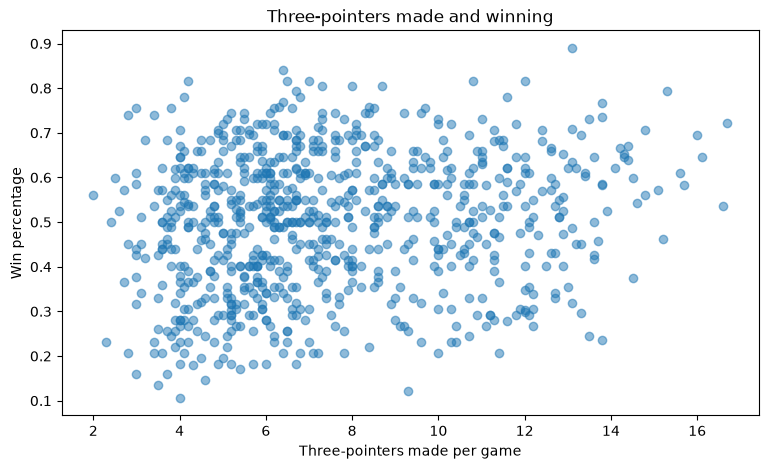

Hypothesis 3 is supported.


In [22]:
h3 = teams[["FG3M", "W_PCT"]].dropna()
middle_threes = h3["FG3M"].median()
more_threes = h3[h3["FG3M"] >= middle_threes]
fewer_threes = h3[h3["FG3M"] < middle_threes]

print("Average win percentage, more made threes:", round(more_threes["W_PCT"].mean(), 3))
print("Average win percentage, fewer made threes:", round(fewer_threes["W_PCT"].mean(), 3))

plt.figure(figsize=(9, 5))
plt.scatter(h3["FG3M"], h3["W_PCT"], alpha=0.5)
plt.title("Three-pointers made and winning")
plt.xlabel("Three-pointers made per game")
plt.ylabel("Win percentage")
plt.show()

if more_threes["W_PCT"].mean() > fewer_threes["W_PCT"].mean():
    print("Hypothesis 3 is supported.")
else:
    print("Hypothesis 3 is not supported.")

### Results

The graph shows how three-pointers made and win percentage compare. Teams making more threes generally had better records, although there are teams with similar three-point numbers and different win percentages. This supports the prediction as a general pattern, but making threes is not the only thing that affects winning.

## Hypothesis 4: Teams with higher field-goal percentages tend to win more games.

We compared each team's field-goal percentage (`FG_PCT`) with its win percentage (`W_PCT`). We split the teams into a higher and lower shooting group and compared their average wins.

Average win percentage, higher shooting: 0.57
Average win percentage, lower shooting: 0.428


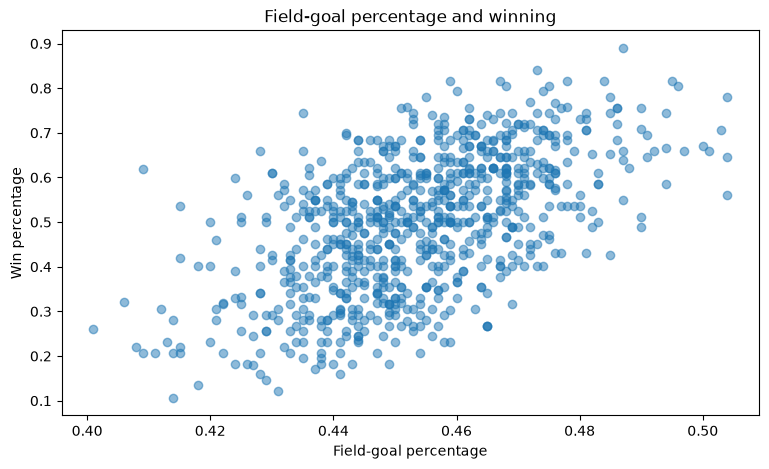

Hypothesis 4 is supported.


In [23]:
h4 = teams[["FG_PCT", "W_PCT"]].dropna()
middle_shooting = h4["FG_PCT"].median()
high_shooting = h4[h4["FG_PCT"] >= middle_shooting]
low_shooting = h4[h4["FG_PCT"] < middle_shooting]

print("Average win percentage, higher shooting:", round(high_shooting["W_PCT"].mean(), 3))
print("Average win percentage, lower shooting:", round(low_shooting["W_PCT"].mean(), 3))

plt.figure(figsize=(9, 5))
plt.scatter(h4["FG_PCT"], h4["W_PCT"], alpha=0.5)
plt.title("Field-goal percentage and winning")
plt.xlabel("Field-goal percentage")
plt.ylabel("Win percentage")
plt.show()

if high_shooting["W_PCT"].mean() > low_shooting["W_PCT"].mean():
    print("Hypothesis 4 is supported.")
else:
    print("Hypothesis 4 is not supported.")

### Results

We used the graph and the two group averages to check the prediction. If the higher-shooting group also has the higher win percentage, it supports our hypothesis. The printed numbers above show which group did better.

## Hypothesis 5: Teams with fewer turnovers tend to win more games.

We compared turnovers per game (`TOV`) with win percentage (`W_PCT`). We split teams into groups with fewer and more turnovers and compared their average win percentages.

Average win percentage:
Fewer turnovers    0.546
More turnovers     0.460
dtype: float64


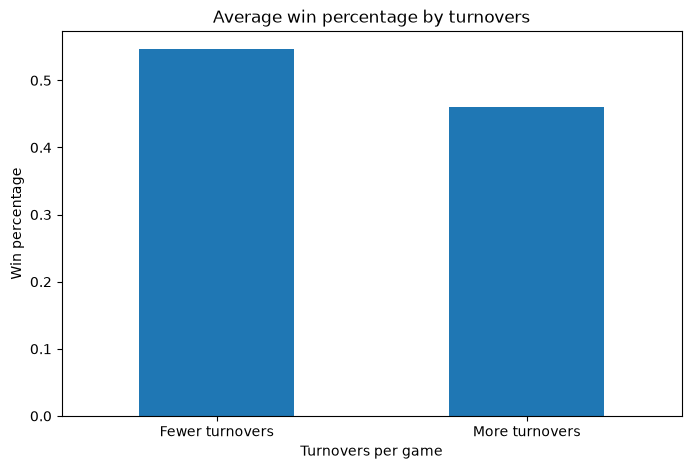

Hypothesis 5 is supported.


In [24]:
h5 = teams[["TOV", "W_PCT"]].dropna()
middle_turnovers = h5["TOV"].median()
fewer_turnovers = h5[h5["TOV"] < middle_turnovers]
more_turnovers = h5[h5["TOV"] >= middle_turnovers]

wins = pd.Series({
    "Fewer turnovers": fewer_turnovers["W_PCT"].mean(),
    "More turnovers": more_turnovers["W_PCT"].mean()
})

print("Average win percentage:")
print(wins.round(3))

wins.plot.bar(figsize=(8, 5))
plt.title("Average win percentage by turnovers")
plt.ylabel("Win percentage")
plt.xlabel("Turnovers per game")
plt.xticks(rotation=0)
plt.show()

if wins["Fewer turnovers"] > wins["More turnovers"]:
    print("Hypothesis 5 is supported.")
else:
    print("Hypothesis 5 is not supported.")

### Results

The bar graph compares the two groups' win percentages. The taller bar shows which group won more often. We used the averages and the result printed above to decide whether fewer turnovers went along with more wins.

## Hypothesis 6: NBA teams scored more points per game in 2022–23 than in 1996–97.

We calculated the average team points per game (`PTS`) for each season. We used a line graph to compare scoring over time.

1996-97 points per game: 96.9
2022-23 points per game: 114.69
Difference: 17.78


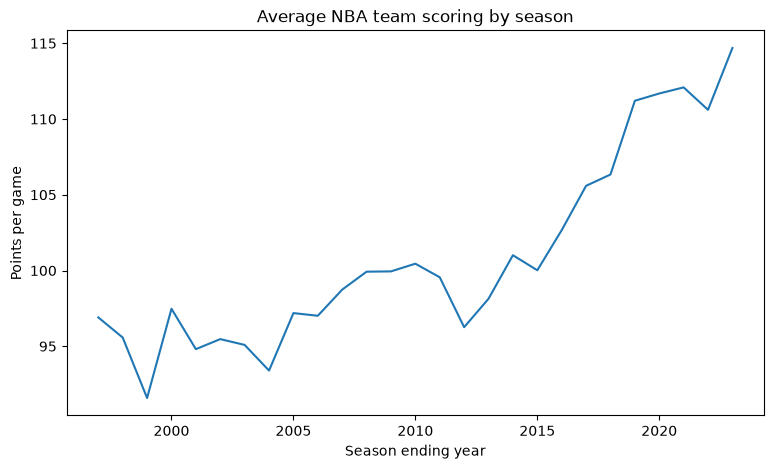

Hypothesis 6 is supported.


In [25]:
scoring = teams.groupby("season_end")["PTS"].mean()
first_season = scoring.loc[1997]
last_season = scoring.loc[2023]

print("1996-97 points per game:", round(first_season, 2))
print("2022-23 points per game:", round(last_season, 2))
print("Difference:", round(last_season - first_season, 2))

scoring.plot(figsize=(9, 5))
plt.title("Average NBA team scoring by season")
plt.xlabel("Season ending year")
plt.ylabel("Points per game")
plt.show()

if last_season > first_season:
    print("Hypothesis 6 is supported.")
else:
    print("Hypothesis 6 is not supported.")

### Results

The line graph shows how average team scoring changed from season to season. The first and last values printed above tell us whether teams scored more in 2022–23. The difference shows how much scoring changed.

## Conclusion

We tested six hypotheses about NBA shooting, scoring, and winning. Centers took more three-pointers over time. Point guards did not have a much larger share of league scoring, even though the game changed. Teams that made more threes generally won more games.

We also compared shooting percentage, turnovers, and scoring over time. The graphs and averages helped us see which predictions matched the data. Overall, we learned that some team stats go along with winning, but there is not just one stat that decides how good a team is.